# 03. Evaluation Metrics from Scratch: Confusion Matrix, Precision, Recall, and Macro-F1

**Task:** T4-004  
**Driver:** Sushil | **Navigator:** Yashwant  
**Concept Note:** [`docs/learning/confusion-matrix-precisionrecall-macrof1.md`](../docs/learning/confusion-matrix-precisionrecall-macrof1.md)  

---

## Executive Summary & Educational Focus

In precision agriculture and hydroponics, crop stress events (such as `pH_Low` or `EC_Low_Deficiency`) are often rare compared to baseline healthy `Normal` states. In highly imbalanced classification problems, standard **Overall Accuracy** is dangerously misleading: a trivial classifier predicting `Normal` on 100% of samples can score >95% accuracy while completely failing to detect crop-threatening anomalies.

This notebook implements fundamental evaluation metrics from first principles using pure **NumPy**:
1. **Multi-Class Confusion Matrix** (rows = ground truth, columns = predicted).
2. **Per-Class True Positives (TP), False Positives (FP), False Negatives (FN), and Support**.
3. **Precision, Recall, and F1-Score per class** with configurable zero-division handling (`zero_division=0.0`).
4. **Macro-Averaged Precision, Recall, and Macro-F1** (unweighted arithmetic mean across classes).
5. **Mathematical Verification:** Exact assertion to machine tolerance against `sklearn.metrics` across both normal and edge-case scenarios (zero predictions, zero support).
6. **Empirical Demonstration:** Why overall accuracy conceals severe rare-class failure in hydroponic diagnosis.

In [1]:
import sys
from pathlib import Path

# Ensure project root is accessible
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report,
)

print(f"NumPy version: {np.__version__}")
print(f"Project root: {ROOT}")

C:\Users\M A SUSHIL KUMAR\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


NumPy version: 2.5.3
Project root: D:\Hydroponic-Nutrition-AI


## 1. Pure NumPy Implementations from First Principles

### 1.1 Multi-Class Confusion Matrix
Given ground truth vector $y_{\text{true}}$ and predicted vector $y_{\text{pred}}$ over $K$ classes:
$$
C_{i, j} = \sum_{n=1}^N \mathbb{I}(y_{\text{true}, n} = \text{labels}[i] \land y_{\text{pred}, n} = \text{labels}[j])
$$
Where:
- Rows ($i$) represent true actual classes.
- Columns ($j$) represent model predictions.
- Diagonal entries $C_{i, i}$ are True Positives for class $i$.

In [2]:
def confusion_matrix_from_scratch(
    y_true: list | np.ndarray,
    y_pred: list | np.ndarray,
    labels: list | np.ndarray | None = None,
) -> tuple[np.ndarray, list]:
    """Compute multi-class confusion matrix from first principles in NumPy.

    Args:
        y_true: Array-like of ground truth labels.
        y_pred: Array-like of predicted labels.
        labels: Optional ordered list of unique labels. If None, sorted unique
                labels appearing in y_true or y_pred are used.

    Returns:
        cm: 2D numpy array of shape (K, K) where cm[i, j] is the count of samples
            with true label i and predicted label j.
        ordered_labels: The ordered list of classes corresponding to rows/columns.
    """
    y_t = np.asarray(y_true)
    y_p = np.asarray(y_pred)
    if len(y_t) != len(y_p):
        raise ValueError("y_true and y_pred must have identical length.")

    if labels is None:
        ordered_labels = sorted(set(y_t).union(set(y_p)))
    else:
        ordered_labels = list(labels)

    label_to_idx = {lbl: idx for idx, lbl in enumerate(ordered_labels)}
    k = len(ordered_labels)
    cm = np.zeros((k, k), dtype=np.int64)

    for t, p in zip(y_t, y_p):
        if t in label_to_idx and p in label_to_idx:
            cm[label_to_idx[t], label_to_idx[p]] += 1

    return cm, ordered_labels

### 1.2 Per-Class and Macro Metrics: Precision, Recall, and F1

For each class $i$:
- $\text{True Positives } (TP_i) = C_{i, i}$
- $\text{False Positives } (FP_i) = \sum_{k \neq i} C_{k, i} = \text{ColumnSum}_i - C_{i, i}$
- $\text{False Negatives } (FN_i) = \sum_{k \neq i} C_{i, k} = \text{RowSum}_i - C_{i, i}$
- $\text{True Negatives } (TN_i) = N - (TP_i + FP_i + FN_i)$
- $\text{Support}_i = \text{RowSum}_i$

Metric definitions:
$$
\text{Precision}_i = \frac{TP_i}{TP_i + FP_i}
$$
$$
\text{Recall}_i = \frac{TP_i}{TP_i + FN_i}
$$
$$
F1_i = 2 \times \frac{\text{Precision}_i \times \text{Recall}_i}{\text{Precision}_i + \text{Recall}_i} = \frac{2 TP_i}{2 TP_i + FP_i + FN_i}
$$

**Macro-Averaging:**
$$
\text{Macro-Precision} = \frac{1}{K} \sum_{i=1}^K \text{Precision}_i, \quad \text{Macro-Recall} = \frac{1}{K} \sum_{i=1}^K \text{Recall}_i, \quad \text{Macro-F1} = \frac{1}{K} \sum_{i=1}^K F1_i
$$

**Zero-Division Convention:**
When a class is never predicted ($TP_i + FP_i = 0$), Precision has a zero denominator. When a class has no positive instances ($TP_i + FN_i = 0$), Recall has a zero denominator. Per standard scikit-learn convention, setting `zero_division=0.0` maps undefined division to `0.0`.

In [3]:
def calculate_metrics_from_scratch(
    y_true: list | np.ndarray,
    y_pred: list | np.ndarray,
    labels: list | np.ndarray | None = None,
    zero_division: float = 0.0,
) -> dict:
    """Compute confusion matrix, per-class, and macro-averaged metrics in NumPy."""
    cm, ordered_labels = confusion_matrix_from_scratch(y_true, y_pred, labels=labels)
    k = len(ordered_labels)

    # Per-class counts
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    support = cm.sum(axis=1)
    total_samples = len(y_true)

    # Per-class Precision
    prec_denom = tp + fp
    precision = np.divide(
        tp, prec_denom,
        out=np.full(k, zero_division, dtype=float),
        where=prec_denom > 0
    )

    # Per-class Recall
    rec_denom = tp + fn
    recall = np.divide(
        tp, rec_denom,
        out=np.full(k, zero_division, dtype=float),
        where=rec_denom > 0
    )

    # Per-class F1-score
    f1_denom = precision + recall
    f1 = np.divide(
        2.0 * precision * recall, f1_denom,
        out=np.full(k, zero_division, dtype=float),
        where=f1_denom > 0
    )

    # Overall Accuracy and Macro Metrics
    accuracy = float(tp.sum()) / float(total_samples) if total_samples > 0 else zero_division
    macro_precision = float(np.mean(precision)) if k > 0 else zero_division
    macro_recall = float(np.mean(recall)) if k > 0 else zero_division
    macro_f1 = float(np.mean(f1)) if k > 0 else zero_division

    per_class = {}
    for idx, lbl in enumerate(ordered_labels):
        per_class[lbl] = {
            "precision": float(precision[idx]),
            "recall": float(recall[idx]),
            "f1": float(f1[idx]),
            "support": int(support[idx]),
            "tp": int(tp[idx]),
            "fp": int(fp[idx]),
            "fn": int(fn[idx]),
        }

    return {
        "confusion_matrix": cm,
        "labels": ordered_labels,
        "accuracy": accuracy,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "per_class": per_class,
    }

## 2. Rigorous Verification Against scikit-learn

We construct a realistic multi-class hydroponic test case comprising 5 classes:
- `Normal` (majority)
- `pH_Low` (rare fault)
- `EC_High` (fault)
- `WaterTemp_High` (fault)
- `Multiple_Stress` (unpredicted fault: **ZERO predictions** to verify zero-division handling)

Additionally, we include a 6th class `EC_Low` in the fixed label vocabulary with **ZERO true instances and ZERO predictions** (zero support).

In [4]:
CLASSES = [
    "EC_High",
    "EC_Low",          # Zero support, zero predictions
    "Multiple_Stress", # Present in ground truth, ZERO predictions
    "Normal",
    "WaterTemp_High",
    "pH_Low",
]

y_true_toy = [
    "Normal", "Normal", "Normal", "Normal", "Normal",
    "Normal", "Normal", "Normal", "Normal", "Normal",
    "pH_Low", "pH_Low", "pH_Low",
    "EC_High", "EC_High", "EC_High", "EC_High",
    "WaterTemp_High", "WaterTemp_High",
    "Multiple_Stress", "Multiple_Stress"  # True cases exist
]

y_pred_toy = [
    "Normal", "Normal", "Normal", "Normal", "Normal",
    "Normal", "Normal", "Normal", "EC_High", "Normal",  # 1 Normal falsely predicted as EC_High
    "pH_Low", "pH_Low", "Normal",                        # 1 pH_Low missed as Normal
    "EC_High", "EC_High", "EC_High", "Normal",         # 1 EC_High missed as Normal
    "WaterTemp_High", "Normal",                         # 1 WaterTemp_High missed as Normal
    "Normal", "Normal"                                  # Multiple_Stress: ZERO PREDICTIONS (predicted as Normal)
]

res_scratch = calculate_metrics_from_scratch(y_true_toy, y_pred_toy, labels=CLASSES, zero_division=0.0)

# Scikit-Learn ground truth
cm_sklearn = confusion_matrix(y_true_toy, y_pred_toy, labels=CLASSES)
acc_sklearn = accuracy_score(y_true_toy, y_pred_toy)
prec_macro_sk = precision_score(y_true_toy, y_pred_toy, labels=CLASSES, average="macro", zero_division=0.0)
rec_macro_sk = recall_score(y_true_toy, y_pred_toy, labels=CLASSES, average="macro", zero_division=0.0)
f1_macro_sk = f1_score(y_true_toy, y_pred_toy, labels=CLASSES, average="macro", zero_division=0.0)

print("=== CONFUSION MATRIX MATCH ===")
print("From-Scratch Confusion Matrix:")
print(res_scratch["confusion_matrix"])
print("\nscikit-learn Confusion Matrix:")
print(cm_sklearn)
np.testing.assert_array_equal(res_scratch["confusion_matrix"], cm_sklearn)
print("✅ Confusion matrix exactly matches scikit-learn!")

print("\n=== GLOBAL METRICS MATCH ===")
print(f"Accuracy:        Scratch={res_scratch['accuracy']:.6f} | Sklearn={acc_sklearn:.6f}")
print(f"Macro-Precision: Scratch={res_scratch['macro_precision']:.6f} | Sklearn={prec_macro_sk:.6f}")
print(f"Macro-Recall:    Scratch={res_scratch['macro_recall']:.6f} | Sklearn={rec_macro_sk:.6f}")
print(f"Macro-F1:        Scratch={res_scratch['macro_f1']:.6f} | Sklearn={f1_macro_sk:.6f}")

np.testing.assert_allclose(res_scratch["accuracy"], acc_sklearn, atol=1e-9)
np.testing.assert_allclose(res_scratch["macro_precision"], prec_macro_sk, atol=1e-9)
np.testing.assert_allclose(res_scratch["macro_recall"], rec_macro_sk, atol=1e-9)
np.testing.assert_allclose(res_scratch["macro_f1"], f1_macro_sk, atol=1e-9)
print("✅ Macro metrics exactly match scikit-learn to machine precision!")

=== CONFUSION MATRIX MATCH ===
From-Scratch Confusion Matrix:
[[3 0 0 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 2 0 0]
 [1 0 0 9 0 0]
 [0 0 0 1 1 0]
 [0 0 0 1 0 2]]

scikit-learn Confusion Matrix:
[[3 0 0 1 0 0]
 [0 0 0 0 0 0]
 [0 0 0 2 0 0]
 [1 0 0 9 0 0]
 [0 0 0 1 1 0]
 [0 0 0 1 0 2]]
✅ Confusion matrix exactly matches scikit-learn!

=== GLOBAL METRICS MATCH ===
Accuracy:        Scratch=0.714286 | Sklearn=0.714286
Macro-Precision: Scratch=0.565476 | Sklearn=0.565476
Macro-Recall:    Scratch=0.469444 | Sklearn=0.469444
Macro-F1:        Scratch=0.494444 | Sklearn=0.494444
✅ Macro metrics exactly match scikit-learn to machine precision!


In [5]:
# Per-class verification
prec_per_sk = precision_score(y_true_toy, y_pred_toy, labels=CLASSES, average=None, zero_division=0.0)
rec_per_sk = recall_score(y_true_toy, y_pred_toy, labels=CLASSES, average=None, zero_division=0.0)
f1_per_sk = f1_score(y_true_toy, y_pred_toy, labels=CLASSES, average=None, zero_division=0.0)

print(f"{'Class':<20} {'Scratch P':<12} {'Sklearn P':<12} {'Scratch R':<12} {'Sklearn R':<12} {'Scratch F1':<12} {'Sklearn F1'}")
print("-" * 90)
for idx, cls in enumerate(CLASSES):
    p_sc = res_scratch["per_class"][cls]["precision"]
    p_sk = prec_per_sk[idx]
    r_sc = res_scratch["per_class"][cls]["recall"]
    r_sk = rec_per_sk[idx]
    f_sc = res_scratch["per_class"][cls]["f1"]
    f_sk = f1_per_sk[idx]
    print(f"{cls:<20} {p_sc:<12.4f} {p_sk:<12.4f} {r_sc:<12.4f} {r_sk:<12.4f} {f_sc:<12.4f} {f_sk:<12.4f}")
    np.testing.assert_allclose(p_sc, p_sk, atol=1e-9)
    np.testing.assert_allclose(r_sc, r_sk, atol=1e-9)
    np.testing.assert_allclose(f_sc, f_sk, atol=1e-9)

print("-" * 90)
print("✅ All per-class metrics match scikit-learn across all 6 classes (including zero predictions)!")

Class                Scratch P    Sklearn P    Scratch R    Sklearn R    Scratch F1   Sklearn F1
------------------------------------------------------------------------------------------
EC_High              0.7500       0.7500       0.7500       0.7500       0.7500       0.7500      
EC_Low               0.0000       0.0000       0.0000       0.0000       0.0000       0.0000      
Multiple_Stress      0.0000       0.0000       0.0000       0.0000       0.0000       0.0000      
Normal               0.6429       0.6429       0.9000       0.9000       0.7500       0.7500      
WaterTemp_High       1.0000       1.0000       0.5000       0.5000       0.6667       0.6667      
pH_Low               1.0000       1.0000       0.6667       0.6667       0.8000       0.8000      
------------------------------------------------------------------------------------------
✅ All per-class metrics match scikit-learn across all 6 classes (including zero predictions)!


## 3. Why Accuracy Hides Rare-Class Failure in Hydroponics

### The Accuracy Paradox
Consider a greenhouse monitoring dataset with 1,000 hourly readings:
- 960 readings are `Normal` (96%)
- 40 readings are critical `pH_Low` stress (4%)

Suppose a defective or lazy model simply predicts `Normal` for **every single sample** ($100\%$ majority class predictions):
- $\text{Accuracy} = \frac{960}{1000} = \mathbf{96.0\%}$
- $\text{Precision}(\text{pH\_Low}) = 0.0$
- $\text{Recall}(\text{pH\_Low}) = \frac{0}{40} = \mathbf{0.0\%}$
- $F1(\text{pH\_Low}) = \mathbf{0.0\%}$
- $\text{Macro-F1} = \frac{F1(\text{Normal}) + F1(\text{pH\_Low})}{2} = \frac{0.9796 + 0.0}{2} = \mathbf{48.98\%}$

An executive looking only at **Accuracy (96%)** would conclude the system is working brilliantly. In reality, **every single crop failure was missed**, leading to crop death. **Macro-F1 (48.98%)** instantly exposes the complete failure of the minority class.

=== THE ACCURACY PARADOX DEMONSTRATION ===
Overall Accuracy:        96.00%
Macro-F1 Score:          48.98%
pH_Low Recall:           0.00% (Missed 100% of stress events!)
Normal Recall:           100.00%


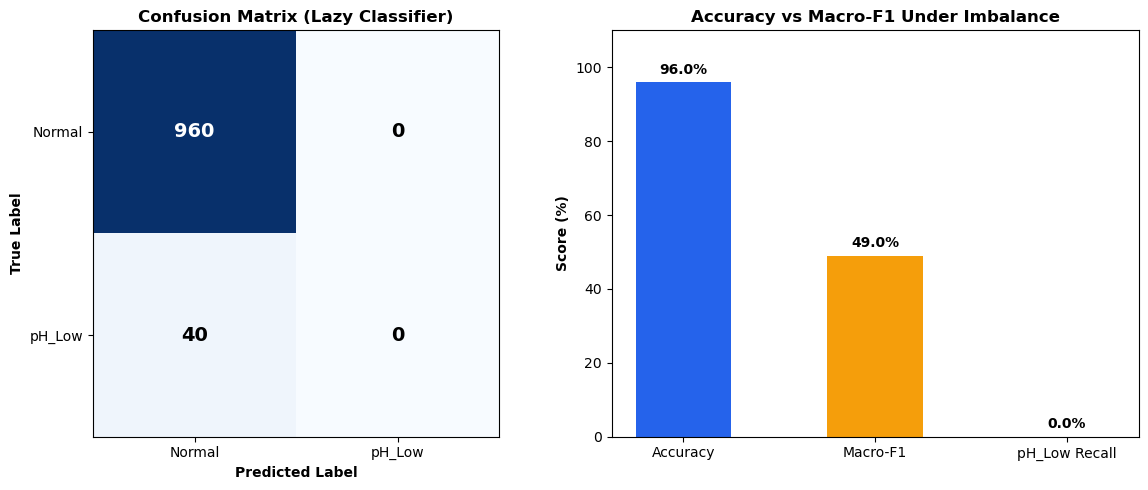

In [6]:
# Synthetic demonstration of the Accuracy Paradox
n_normal = 960
n_stress = 40

y_true_imbalanced = ["Normal"] * n_normal + ["pH_Low"] * n_stress
y_pred_lazy = ["Normal"] * (n_normal + n_stress)  # Always predicts Normal

paradox_metrics = calculate_metrics_from_scratch(y_true_imbalanced, y_pred_lazy, labels=["Normal", "pH_Low"])

print("=== THE ACCURACY PARADOX DEMONSTRATION ===")
print(f"Overall Accuracy:        {paradox_metrics['accuracy']*100:.2f}%")
print(f"Macro-F1 Score:          {paradox_metrics['macro_f1']*100:.2f}%")
print(f"pH_Low Recall:           {paradox_metrics['per_class']['pH_Low']['recall']*100:.2f}% (Missed 100% of stress events!)")
print(f"Normal Recall:           {paradox_metrics['per_class']['Normal']['recall']*100:.2f}%")

# Visualization
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix visualization
cm_p = paradox_metrics["confusion_matrix"]
im = ax[0].imshow(cm_p, cmap="Blues", interpolation="nearest")
ax[0].set_title("Confusion Matrix (Lazy Classifier)", fontsize=12, fontweight="bold")
ax[0].set_xticks([0, 1])
ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(["Normal", "pH_Low"])
ax[0].set_yticklabels(["Normal", "pH_Low"])
ax[0].set_xlabel("Predicted Label", fontweight="bold")
ax[0].set_ylabel("True Label", fontweight="bold")
for i in range(2):
    for j in range(2):
        color = "white" if cm_p[i, j] > 500 else "black"
        ax[0].text(j, i, str(cm_p[i, j]), ha="center", va="center", color=color, fontsize=14, fontweight="bold")

# Metric Comparison Bar Chart
metric_names = ["Accuracy", "Macro-F1", "pH_Low Recall"]
metric_values = [
    paradox_metrics["accuracy"] * 100,
    paradox_metrics["macro_f1"] * 100,
    paradox_metrics["per_class"]["pH_Low"]["recall"] * 100,
]
colors = ["#2563eb", "#f59e0b", "#ef4444"]

bars = ax[1].bar(metric_names, metric_values, color=colors, width=0.5)
ax[1].set_ylim(0, 110)
ax[1].set_ylabel("Score (%)", fontweight="bold")
ax[1].set_title("Accuracy vs Macro-F1 Under Imbalance", fontsize=12, fontweight="bold")
for bar in bars:
    h = bar.get_height()
    ax[1].annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                   xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Summary & Project Takeaways

1. **Macro-F1 is the Primary Decision Metric:** Because it weights every failure class equally regardless of support, Macro-F1 prevents classifiers from ignoring rare diagnostic categories.
2. **Zero-Division Protocol:** All evaluation metrics in Phase 4 and Phase 6 must pass `zero_division=0.0` to ensure determinism when candidate models produce zero predictions for a specific class.
3. **Fixed Class Ordering:** Confusion matrices and classification vectors must follow the fixed, explicit class ordering defined in `ml.sensor_models.schemas` (`CROP_SENSOR_SCHEMAS[crop].classes`).